# Module 4 · Notebook 1: The KV cache

Module 3 trained a GPT, and sampling from it is slow: about 10 seconds for 300 characters. The reason is that every new character re-runs the model on the **whole** context, although everything except the last position was already computed for the previous character.

**Question for this module:** how much faster does generation get with a KV cache, and how much memory does the cache cost as the context grows?

This notebook builds the cache and proves it gives exactly the same model. Notebook 2 measures speed and memory.

| Step | What we do | Proof |
|---|---|---|
| 1 | The trained model from Module 3, with a plain-NumPy forward pass for inference | same logits as the engine |
| 2 | Why caching is allowed at all | appending a token never changes the earlier positions |
| 3 | What has to be cached: keys and values | — |
| 4 | Prefill and decode with a cache | — |
| 5 | Cached vs uncached generation | the same logits at every step, the same text |
| 6 | A first timing | — |
| 7 | The limit: 128 positions, and why the cache can't just slide | a naive sliding cache gives wrong logits |

In [1]:
import sys, time, math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# the model, tokenizer and checkpoint from Module 3 (gpt.py also puts 01 and 02 on the path)
LAB = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(LAB / "03-gpt"))
from gpt import load_checkpoint, gpt as gpt_engine, Tensor, next_probs

print("python", sys.version.split()[0], "| numpy", np.__version__)

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})

python 3.12.15 | numpy 2.5.3


## Step 1: The trained model, and a forward pass for inference

The checkpoint is the one Module 3 saved (best val loss 1.417).

For generation we never need gradients, so building the autograd graph is wasted work: every op would allocate a gradient array, and Module 3 found the graphs also have to be garbage-collected. So inference gets its own forward pass in plain NumPy. It is the same model, line by line: token + position embedding, 4 pre-LN blocks, final LayerNorm, tied output layer.

In [2]:
p, cfg, tok, info = load_checkpoint(LAB / "03-gpt" / "checkpoints" / "gpt.npz")
L, H, C, T_MAX, V = cfg["L"], cfg["H"], cfg["C"], cfg["T"], cfg["V"]
HS = C // H
print(f"checkpoint from step {info['step']}, val loss {info['val']:.3f}")
print(f"layers {L}, heads {H} (head size {HS}), width {C}, context {T_MAX}, vocab {V}")

def layer_norm(x, g, b, eps=1e-5):
    xc = x - x.mean(-1, keepdims=True)
    return xc * ((xc**2).mean(-1, keepdims=True) + eps)**-0.5 * g + b

def gelu(x):
    return 0.5 * x * (1 + np.tanh(math.sqrt(2 / math.pi) * (x + 0.044715 * x**3)))

def softmax(z):
    e = np.exp(z - z.max(-1, keepdims=True))
    return e / e.sum(-1, keepdims=True)

def heads(a):
    # (B, T, C) -> (B, H, T, HS)
    B, T, _ = a.shape
    return a.reshape(B, T, H, HS).transpose(0, 2, 1, 3)

def forward(p, idx):
    # idx (B, T) -> logits (B, T, V). the whole sequence, every time: what sample.py in Module 3 does
    B, T = idx.shape
    x = p["wte"][idx] + p["wpe"][:T]
    mask = np.triu(np.full((T, T), -np.inf), k=1)
    for i in range(L):
        g = lambda k: p[f"h{i}.{k}"]
        h = layer_norm(x, g("ln1_g"), g("ln1_b"))
        q, k, v = heads(h @ g("Wq")), heads(h @ g("Wk")), heads(h @ g("Wv"))
        a = softmax(q @ k.transpose(0, 1, 3, 2) / math.sqrt(HS) + mask)
        x = x + (a @ v).transpose(0, 2, 1, 3).reshape(B, T, C) @ g("Wo")
        h = layer_norm(x, g("ln2_g"), g("ln2_b"))
        x = x + gelu(h @ g("W1") + g("b1")) @ g("W2") + g("b2")
    return layer_norm(x, p["lnf_g"], p["lnf_b"]) @ p["wte"].T

# proof: the same logits as the engine from Modules 1-3, on a real sentence
text = "“I have no data yet. It is a capital mistake to theorise before one has data.”"
idx = tok.encode(text)[None]
ours = forward(p, idx)
engine = gpt_engine({k: Tensor(v) for k, v in p.items()}, idx, cfg).data
print(f"\n{idx.shape[1]} characters: max |numpy forward - engine| = {np.abs(ours - engine).max():.1e}")

checkpoint from step 2250, val loss 1.417
layers 4, heads 4 (head size 32), width 128, context 128, vocab 88

78 characters: max |numpy forward - engine| = 1.4e-14


Equal to rounding error, so everything below is the trained model.

## Step 2: Why caching is allowed at all

Generation is a loop: feed the text so far, take the logits at the **last** position, pick a character, append it, repeat. Each round runs the whole sequence again.

That is only wasteful if the earlier positions come out the same every time. They do, because of the causal mask from Module 2: position $t$ only looks at positions $0 \dots t$, so appending a character at the end cannot change anything before it. Module 3 tested this by changing the last character; here is the same thing for *appending* one:

In [3]:
short = idx[:, :40]
longer = idx[:, :41]                     # the same 40 characters plus one more
a, b = forward(p, short), forward(p, longer)
print(f"max change in the logits at positions 0..39 after appending a character: {np.abs(a - b[:, :40]).max():.1e}")

max change in the logits at positions 0..39 after appending a character: 0.0e+00


(If this prints 0.0, nothing changed at all. A difference around $10^{-15}$ would also be fine: NumPy can pick a different order for its sums when the matrices have a different shape.)

So at every step of generation, all positions but the new one are recomputed for nothing. For our model, the work per new character is roughly:

| | per new character, context of length $t$ |
|---|---|
| without a cache | the whole model on $t$ positions |
| with a cache | the whole model on **1** position, plus attention over the $t$ cached ones |

So the saving should grow with the context. Notebook 2 measures how much.

## Step 3: What has to be cached

What does the new position actually need from the earlier ones? Look at one attention layer. The new token makes a **query** and compares it with the **keys** of all earlier tokens, then takes a weighted average of their **values**. That is the only place in the whole model where positions talk to each other: LayerNorm, the MLP and the residual adds all work on each position on its own.

So per layer, the new token needs the keys and values of every earlier position, and nothing else:

- **keys and values** of the past tokens: needed, and they never change (Step 2), so compute them once and keep them. That is the **KV cache**;
- **queries** of the past tokens: never needed again, a query is only used by its own position;
- the past positions' **outputs**: never needed again either.

Size of the cache: 2 (keys and values) × layers × positions × width numbers, per sequence. For this model at the full 128 positions:

In [4]:
n_cache = 2 * L * T_MAX * C
n_params = sum(v.size for v in p.values())
print(f"cache at {T_MAX} positions: 2 x {L} x {T_MAX} x {C} = {n_cache:,} numbers = {n_cache * 8 / 1e6:.2f} MB in float64")
print(f"the model itself: {n_params:,} numbers = {n_params * 8 / 1e6:.2f} MB")

cache at 128 positions: 2 x 4 x 128 x 128 = 131,072 numbers = 1.05 MB in float64
the model itself: 818,944 numbers = 6.55 MB


Small here: a sixth of the model. It grows with the context, the number of layers and the width, and it is per sequence. Notebook 2 works out what it is for real models.

## Step 4: Prefill and decode

The cache is two arrays per layer, allocated once for the maximum context, plus a counter of how many positions are filled. One function does both phases:

- **prefill**: run the prompt (many tokens at once) and fill the cache;
- **decode**: run one new token, append its key and value, attend over everything in the cache.

The only new detail is the mask. The new tokens sit at positions $n, n+1, \dots$ after $n$ cached ones. New token $j$ may see cached positions $0 \dots n+j$: all of the cache, and the new tokens up to itself.

In [5]:
def new_cache(B=1):
    return {"k": np.zeros((L, B, H, T_MAX, HS)), "v": np.zeros((L, B, H, T_MAX, HS)), "n": 0}

def forward_cached(p, idx, cache):
    # idx (B, t): only the NEW tokens. appends their keys/values to the cache, returns their logits (B, t, V)
    B, t = idx.shape
    n = cache["n"]
    assert n + t <= T_MAX, "the cache is full: the model only has 128 positions (Step 7)"
    x = p["wte"][idx] + p["wpe"][n:n + t]
    mask = np.triu(np.full((t, n + t), -np.inf), k=n + 1)          # new token j sees positions 0 .. n + j
    for i in range(L):
        g = lambda k: p[f"h{i}.{k}"]
        h = layer_norm(x, g("ln1_g"), g("ln1_b"))
        q = heads(h @ g("Wq"))
        cache["k"][i, :, :, n:n + t] = heads(h @ g("Wk"))           # only the new keys and values are computed
        cache["v"][i, :, :, n:n + t] = heads(h @ g("Wv"))
        K, Vv = cache["k"][i, :, :, :n + t], cache["v"][i, :, :, :n + t]
        a = softmax(q @ K.transpose(0, 1, 3, 2) / math.sqrt(HS) + mask)
        x = x + (a @ Vv).transpose(0, 2, 1, 3).reshape(B, t, C) @ g("Wo")
        h = layer_norm(x, g("ln2_g"), g("ln2_b"))
        x = x + gelu(h @ g("W1") + g("b1")) @ g("W2") + g("b2")
    cache["n"] = n + t
    return layer_norm(x, p["lnf_g"], p["lnf_b"]) @ p["wte"].T

# prefilling the whole sentence at once must give exactly forward()
cache = new_cache()
pre = forward_cached(p, idx, cache)
print(f"prefill of {idx.shape[1]} tokens vs forward(): max diff {np.abs(pre - ours).max():.1e}, cache now holds {cache['n']} positions")

# and so must feeding it one character at a time
cache = new_cache()
one_by_one = np.concatenate([forward_cached(p, idx[:, j:j + 1], cache) for j in range(idx.shape[1])], axis=1)
print(f"one token at a time vs forward():  max diff {np.abs(one_by_one - ours).max():.1e}")

prefill of 78 tokens vs forward(): max diff 0.0e+00, cache now holds 78 positions
one token at a time vs forward():  max diff 1.6e-14


## Step 5: Cached vs uncached generation

The real test: generate with both and compare the logits at **every** step. Greedy first (always the most likely character, so any difference would show up as different text), then sampling with the same seed. Both continue the same prompt up to the full 128 positions.

In [6]:
def generate_uncached(prompt, n, rng, **kw):
    ids = list(tok.encode(prompt))
    all_logits = []
    for _ in range(n):
        logits = forward(p, np.array(ids)[None])[0, -1]           # the whole sequence again
        all_logits.append(logits)
        ids.append(rng.choice(V, p=next_probs(logits, **kw)))
    return tok.decode(ids), np.array(all_logits)

def generate_cached(prompt, n, rng, **kw):
    ids = list(tok.encode(prompt))
    cache = new_cache()
    logits = forward_cached(p, np.array(ids)[None], cache)[0, -1] # prefill the prompt
    all_logits = []
    for _ in range(n):
        all_logits.append(logits)
        ids.append(rng.choice(V, p=next_probs(logits, **kw)))
        logits = forward_cached(p, np.array([[ids[-1]]]), cache)[0, -1]   # decode: only the new token
    return tok.decode(ids), np.array(all_logits)

prompt = "Holmes"
n_new = T_MAX - len(prompt)
for kw in [{"temperature": 0}, {"temperature": 0.8}]:
    t_u, l_u = generate_uncached(prompt, n_new, np.random.default_rng(0), **kw)
    t_c, l_c = generate_cached(prompt, n_new, np.random.default_rng(0), **kw)
    print(f"{kw}: {n_new} steps, max logit difference over all steps {np.abs(l_u - l_c).max():.1e}, "
          f"same text: {t_u == t_c}")
print()
print(t_c)

{'temperature': 0}: 122 steps, max logit difference over all steps 2.0e-14, same text: True
{'temperature': 0.8}: 122 steps, max logit difference over all steps 2.0e-14, same text: True

Holmes gammed dried
the fearsal wound from the fire. She him brought of him in the writing powerson.”

“What will be an insigati


The same logits at every one of the 122 steps, to rounding error, and character for character the same text. The cache changes how much work is done, not what the model computes.

## Step 6: A first timing

How long does each new character take, as the context fills up? Same prompt, greedy, timing every step.

per new character      at context 10    at context 127
  without cache            1.96 ms        14.41 ms
  with cache               0.82 ms         1.12 ms

all 122 characters: 1.01 s without, 0.10 s with (9.9x)


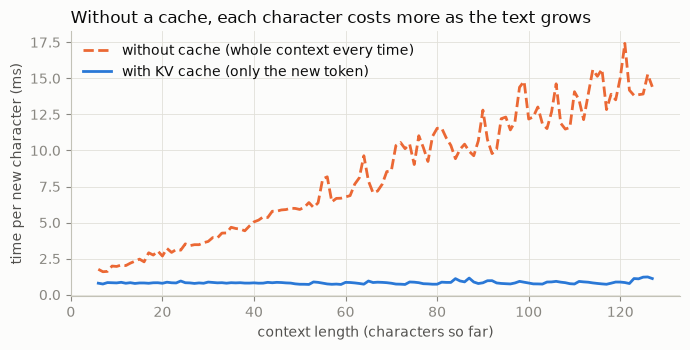

In [7]:
def time_steps(cached, prompt="Holmes", repeats=3):
    # seconds per new token at each context length, best of a few repeats (timings are noisy)
    best = None
    for _ in range(repeats):
        ids = list(tok.encode(prompt))
        cache = new_cache()
        if cached:
            logits = forward_cached(p, np.array(ids)[None], cache)[0, -1]
        times = []
        while len(ids) < T_MAX:
            t0 = time.perf_counter()
            if cached:
                ids.append(int(np.argmax(logits)))
                logits = forward_cached(p, np.array([[ids[-1]]]), cache)[0, -1]
            else:
                logits = forward(p, np.array(ids)[None])[0, -1]
                ids.append(int(np.argmax(logits)))
            times.append(time.perf_counter() - t0)
        best = np.array(times) if best is None else np.minimum(best, times)
    return best

t_unc, t_cac = time_steps(False), time_steps(True)
ctx = np.arange(len("Holmes"), T_MAX)
print(f"per new character      at context 10    at context 127")
print(f"  without cache        {t_unc[10 - 6] * 1e3:8.2f} ms     {t_unc[-1] * 1e3:8.2f} ms")
print(f"  with cache           {t_cac[10 - 6] * 1e3:8.2f} ms     {t_cac[-1] * 1e3:8.2f} ms")
print(f"\nall {len(ctx)} characters: {t_unc.sum():.2f} s without, {t_cac.sum():.2f} s with ({t_unc.sum() / t_cac.sum():.1f}x)")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(ctx, t_unc * 1e3, color=SERIES[1], ls="--", label="without cache (whole context every time)")
ax.plot(ctx, t_cac * 1e3, color=SERIES[0], label="with KV cache (only the new token)")
ax.set_xlabel("context length (characters so far)")
ax.set_ylabel("time per new character (ms)")
ax.set_title("Without a cache, each character costs more as the text grows", loc="left")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

Without the cache, the time per character grows roughly in a straight line with the context: from ~2 ms at 10 characters to ~15 ms at 127, because every step redoes the whole sequence. With the cache it stays flat at ~1 ms: one position's worth of work, plus attention over the cache, which at 128 positions is still tiny. Over all 122 characters that is about 9× faster (1.0 s against 0.11 s on this laptop; the exact times depend on the machine and jump around from run to run).

Two things to keep in mind before reading too much into the 9×:

- the plain-NumPy forward is already faster than Module 3's `sample.py`, which went through the autograd engine and took ~10 s for 300 characters. Building no graph helps on its own;
- at this size the cached step is mostly Python and NumPy overhead (a few dozen small array operations per layer), not arithmetic, which is why it is flat.

Notebook 2 separates those and goes to much longer contexts.

## Step 7: The limit, and why the cache can't just slide

This model has a learned position embedding with **128 rows**, so it simply has no position 128. Module 3's `sample.py` handles longer texts by cropping: it always feeds the *last* 128 characters. Then the oldest character drops out, and every remaining one moves one position to the left.

Can the cache do the same, drop the oldest key and value and keep going? No. Each cached key was computed from its token's embedding **plus its position embedding** at the time. After the shift, the token that was at position 50 should now be at 49, but its cached key still says 50. Every key in the cache is now wrong.

The proof: fill the cache to 128, then for 50 more characters compare a naive sliding cache against recomputing the last 128 characters from scratch (what `sample.py` does).

In [8]:
ids = list(tok.encode(prompt))
cache = new_cache()
logits = forward_cached(p, np.array(ids)[None], cache)[0, -1]
while len(ids) < T_MAX:                                     # fill the cache to all 128 positions, greedily
    ids.append(int(np.argmax(logits)))
    logits = forward_cached(p, np.array([[ids[-1]]]), cache)[0, -1]
assert cache["n"] == T_MAX

right = logits                                              # with 128 tokens the cache is still exact
diffs, agree = [], []
for step in range(50):
    ids.append(int(np.argmax(right)))                       # the next character, from the correct model
    right = forward(p, np.array(ids[-T_MAX:])[None])[0, -1] # recompute the last 128 from scratch
    # naive slide: drop the oldest cached position, put the newest token at the last position
    cache["k"][:, :, :, :-1] = cache["k"][:, :, :, 1:].copy()
    cache["v"][:, :, :, :-1] = cache["v"][:, :, :, 1:].copy()
    cache["n"] = T_MAX - 1
    wrong = forward_cached(p, np.array([[ids[-1]]]), cache)[0, -1]
    diffs.append(np.abs(right - wrong).max())
    agree.append(np.argmax(right) == np.argmax(wrong))

print(f"naive sliding cache vs recomputing, over 50 steps past the limit:")
print(f"  largest logit difference {max(diffs):.2f} (median {np.median(diffs):.2f})")
print(f"  same most-likely next character in {np.mean(agree):.0%} of the steps")

naive sliding cache vs recomputing, over 50 steps past the limit:
  largest logit difference 12.89 (median 6.73)
  same most-likely next character in 10% of the steps


Off by up to ~13 in the logits, and the most likely next character agrees in only 10% of the steps: the naive sliding cache is a different, broken model. The only correct option past the limit is to recompute the whole window every step, which is what `sample.py` does, and then the cache saves nothing.

So with learned absolute positions, the cache only works up to the model's context length. Real LLMs mostly avoid hitting this by being trained on much longer contexts (thousands of tokens).

## Summary

- **Inference gets its own forward pass** in plain NumPy, with no autograd graph. It matches the engine to 1e-14.
- **Caching is allowed because of the causal mask**: appending a character changes the earlier positions by exactly 0.
- **Only keys and values need caching**: 2 × layers × positions × width numbers per sequence. That's 1.05 MB at 128 positions here, a sixth of the model.
- **Cached = uncached**: the logits agree to 2e-14 over all 122 steps, and the text is identical, greedy and sampled.
- **Per character**: flat ~1 ms with the cache, against up to ~15 ms without; about 9× over a full 128-character context on this laptop.
- **The limit**: with learned absolute positions the cache can't slide past 128. A naive slide agrees with the real model only 10% of the time.

## Next: Notebook 2, the experiment

How the time per token and the cache's memory grow with the context, and where the crossover is, measured for context lengths far beyond 128.